# DSC680 Project 1 Analysis
## Predicting Calls-for-Service Demand to Support Operational Staffing Readiness
**Adam A. Saenz**

This notebook reproduces the data preparation, exploratory analysis, feature engineering, time-aware validation, model fitting, and evaluation used in the final Project 1 report. The outcome is **hourly calls-for-service demand**, not confirmed crime.

## Data requirements and reproducibility
The analysis expects the 24 SAPD historical export files to be stored in the same folder as this notebook and named `ExcelReport*.aspx`. The files cover eight weeks (September 1 through October 26, 2025) and three dispatch categories: Traffic Calls, Property Crime Calls, and Crimes Against Person Calls. The notebook keeps the raw exports unchanged and performs all filtering and transformations in code.

The public source is the City of San Antonio / SAPD Police Response and historical calls-for-service data. A call for service is treated here as an operational workload event, not evidence that a crime occurred.

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import glob, os

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix
)

plt.rcParams["figure.figsize"] = (8, 4.5)

## 1. Ingest and validate the source exports
Each export is an HTML table saved with an `.aspx` extension. The largest table in each file contains the call-level records. Timestamps are parsed with the source format explicitly specified, the intended study window is enforced, and incident numbers are checked for overlap before de-duplication. The final row-count assertion is a reproducibility check against the validated study dataset.

In [9]:
files = sorted(glob.glob("ExcelReport*.aspx"))
print(f"Source files found: {len(files)}")
if len(files) != 24:
    raise ValueError(f"Expected 24 SAPD exports, but found {len(files)}.")

frames = []
for f in files:
    tables = pd.read_html(f)
    df = max(tables, key=len).copy()
    df["Response Date"] = pd.to_datetime(
        df["Response Date"], format="%m/%d/%Y %I:%M:%S %p", errors="coerce"
    )
    df["Source File"] = os.path.basename(f)
    frames.append(df)

raw_all = pd.concat(frames, ignore_index=True)
print("Raw rows before study-window filter:", len(raw_all))
print("Rows on/after 2025-10-27:", (raw_all["Response Date"] >= "2025-10-27").sum())

raw_all = raw_all[
    (raw_all["Response Date"] >= "2025-09-01") &
    (raw_all["Response Date"] < "2025-10-27")
].copy()

dup_mask = raw_all.duplicated(subset=["Incident Number"], keep=False)
dup_rows = raw_all.loc[dup_mask, ["Incident Number", "Source File"]].copy()
if dup_rows.empty:
    print("No overlapping incident numbers were found.")
else:
    print("Overlapping incident records:", len(dup_rows))

raw = (
    raw_all.sort_values(["Response Date", "Source File"])
    .drop_duplicates(subset=["Incident Number"], keep="first")
    .copy()
)

print("\nFinal validation")
print("Rows:", len(raw))
print("Unique incidents:", raw["Incident Number"].nunique())
print("Duplicate incidents:", raw["Incident Number"].duplicated().sum())
print("Missing response dates:", raw["Response Date"].isna().sum())
print("Missing ZIP codes:", raw["Zipcode"].isna().sum())
print("Missing HOA values:", raw["HOA"].isna().sum())

EXPECTED_ROWS = 71361
assert len(raw) == EXPECTED_ROWS
assert raw["Incident Number"].nunique() == EXPECTED_ROWS
assert raw["Incident Number"].duplicated().sum() == 0
assert raw["Response Date"].isna().sum() == 0
print("Validation passed: 71,361 unique incidents.")

Source files found: 24
Raw rows before study-window filter: 71362
Rows on/after 2025-10-27: 1
No overlapping incident numbers were found.

Final validation
Rows: 71361
Unique incidents: 71361
Duplicate incidents: 0
Missing response dates: 0
Missing ZIP codes: 61
Missing HOA values: 42066
Validation passed: 71,361 unique incidents.


## 2. Descriptive analysis and research-question context
The primary modeling target is citywide hourly demand. Descriptive summaries are also used to address the supporting question about **time, day, call type, and geography**. Geographic counts are interpreted cautiously: raw call volume is not a population-adjusted crime rate and can reflect population, traffic, commercial activity, reporting behavior, and police practices.

In [10]:
category_counts = raw["Category"].value_counts()
category_pct = (category_counts / len(raw) * 100).round(1)
category_summary = pd.DataFrame({"calls": category_counts, "percent": category_pct})
print("Call-type mix")
print(category_summary)

print("\nCouncil District raw call counts")
district_counts = raw["Council District"].value_counts().sort_index()
print(district_counts)

raw["hour"] = raw["Response Date"].dt.floor("h")
idx = pd.date_range("2025-09-01", "2025-10-26 23:00:00", freq="h")
hourly = raw.groupby("hour").size().reindex(idx, fill_value=0).rename("calls").to_frame()

print("\nHourly summary")
print(hourly["calls"].describe(percentiles=[.8]))

by_hour = hourly.assign(hour_of_day=hourly.index.hour).groupby("hour_of_day")["calls"].mean()
by_day = hourly.assign(day_of_week=hourly.index.dayofweek).groupby("day_of_week")["calls"].mean()
weekly = hourly["calls"].resample("W-SUN").sum()
print("\nPeak average hour:", int(by_hour.idxmax()), round(by_hour.max(), 1))
print("Highest average day index (Mon=0):", int(by_day.idxmax()), round(by_day.max(), 1))
print("Weekly totals:", weekly.to_dict())

# Category-specific peak hour helps describe how call type relates to total demand.
raw["hour_of_day"] = raw["Response Date"].dt.hour
category_peak = (
    raw.groupby(["Category", "hour_of_day"]).size().div(56)
    .rename("avg_calls_per_hour").reset_index()
    .sort_values(["Category", "avg_calls_per_hour"], ascending=[True, False])
    .groupby("Category").head(1)
)
print("\nCategory-specific peak hour")
print(category_peak.to_string(index=False))

Call-type mix
                             calls  percent
Category                                   
Traffic Calls                34463     48.3
Property Crime Calls         19413     27.2
Crimes Against Person Calls  17485     24.5

Council District raw call counts
Council District
0       496
1     10946
2      8423
3      7106
4      6493
5      8053
6      6093
7      5479
8      6772
9      6745
10     4755
Name: count, dtype: int64

Hourly summary
count    1344.000000
mean       53.095982
std        26.654691
min         4.000000
50%        52.000000
80%        76.400000
max       141.000000
Name: calls, dtype: float64

Peak average hour: 14 84.6
Highest average day index (Mon=0): 1 59.0
Weekly totals: {Timestamp('2025-09-07 00:00:00'): 8389, Timestamp('2025-09-14 00:00:00'): 9030, Timestamp('2025-09-21 00:00:00'): 8755, Timestamp('2025-09-28 00:00:00'): 9044, Timestamp('2025-10-05 00:00:00'): 9036, Timestamp('2025-10-12 00:00:00'): 8608, Timestamp('2025-10-19 00:00:00'): 8630, 

## 3. Reproduce the report visualizations
The figures below reproduce the four illustrations used in the final report. The dashed line on the hour-of-day figure is the training-period elevated-demand threshold.

Training-only 80th percentile threshold: 75.0


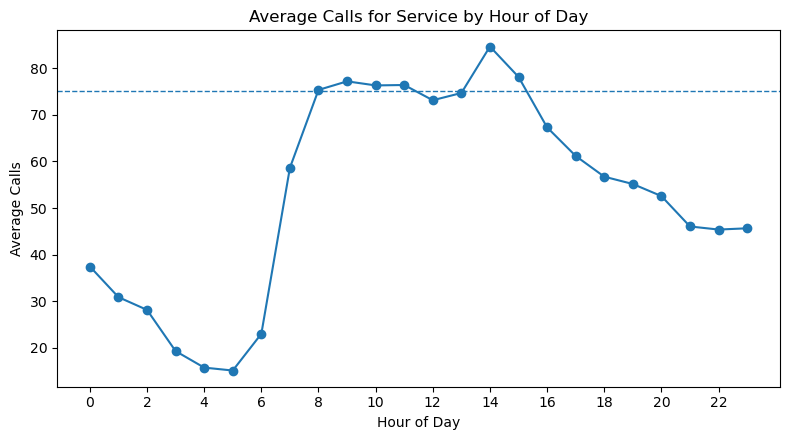

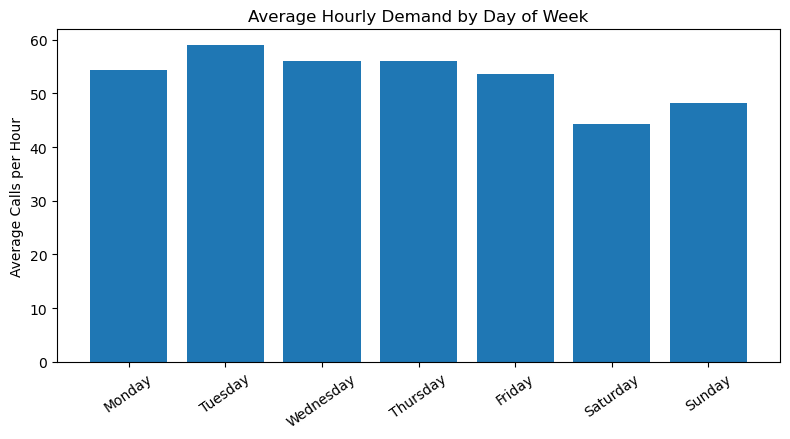

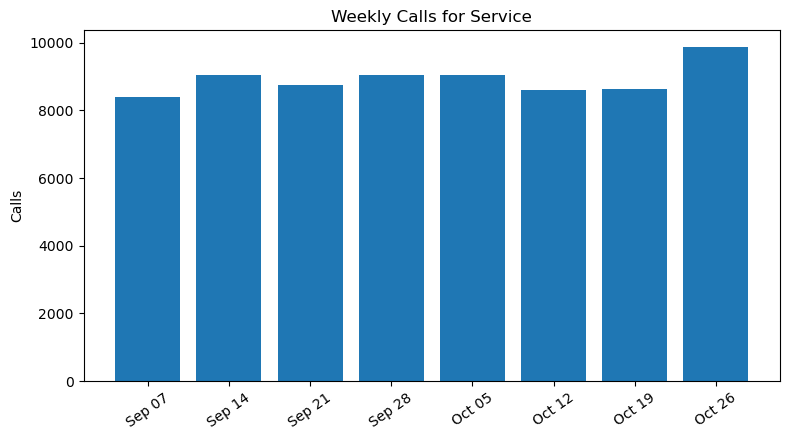

In [11]:
split = pd.Timestamp("2025-10-13")
threshold = hourly.loc[hourly.index < split, "calls"].quantile(.80)
print("Training-only 80th percentile threshold:", threshold)

fig, ax = plt.subplots()
ax.plot(by_hour.index, by_hour.values, marker="o")
ax.axhline(threshold, linestyle="--", linewidth=1)
ax.set_title("Average Calls for Service by Hour of Day")
ax.set_xlabel("Hour of Day")
ax.set_ylabel("Average Calls")
ax.set_xticks(range(0,24,2))
plt.tight_layout(); plt.show()

fig, ax = plt.subplots()
labels = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
ax.bar(labels, by_day.values)
ax.set_title("Average Hourly Demand by Day of Week")
ax.set_ylabel("Average Calls per Hour")
ax.tick_params(axis="x", rotation=35)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots()
ax.bar([d.strftime("%b %d") for d in weekly.index], weekly.values)
ax.set_title("Weekly Calls for Service")
ax.set_ylabel("Calls")
ax.tick_params(axis="x", rotation=35)
plt.tight_layout(); plt.show()

## 4. Feature engineering and leakage control
The forecast row for hour *t* uses calendar information for hour *t* plus historical demand observed before that hour. Current-hour category counts are deliberately excluded because they would only be known after calls arrive and would leak target information. The 168-hour lag captures the same hour one week earlier.

In [12]:
hourly["hour_of_day"] = hourly.index.hour
hourly["day_of_week"] = hourly.index.dayofweek
hourly["weekend"] = (hourly["day_of_week"] >= 5).astype(int)
hourly["hour_sin"] = np.sin(2*np.pi*hourly["hour_of_day"]/24)
hourly["hour_cos"] = np.cos(2*np.pi*hourly["hour_of_day"]/24)
hourly["dow_sin"] = np.sin(2*np.pi*hourly["day_of_week"]/7)
hourly["dow_cos"] = np.cos(2*np.pi*hourly["day_of_week"]/7)
for lag in [1, 2, 24, 168]:
    hourly[f"lag{lag}"] = hourly["calls"].shift(lag)
hourly["roll24_mean"] = hourly["calls"].shift(1).rolling(24).mean()
hourly["roll24_std"] = hourly["calls"].shift(1).rolling(24).std()
hourly["roll168_mean"] = hourly["calls"].shift(1).rolling(168).mean()

hourly["high_demand"] = (hourly["calls"] >= threshold).astype(int)
features = [
    "hour_sin","hour_cos","dow_sin","dow_cos","weekend",
    "lag1","lag2","lag24","lag168","roll24_mean","roll24_std","roll168_mean"
]
model_df = hourly.dropna(subset=features).copy()
train = model_df[model_df.index < split].copy()
test = model_df[model_df.index >= split].copy()
print("Development rows:", len(train))
print("Holdout rows:", len(test))
print("Holdout elevated-demand hours:", int(test["high_demand"].sum()))

Development rows: 840
Holdout rows: 336
Holdout elevated-demand hours: 79


## 5. Model selection and time-aware validation
**Logistic regression** is the interpretable baseline because it provides a simple linear decision boundary after feature scaling. **Random forest** is the nonlinear challenger because it can capture interactions and threshold effects among lagged demand and recurring calendar patterns.

A random cross-validation split would be inappropriate for this time-ordered forecasting problem because it can allow later observations to inform evaluation of earlier observations. Instead, the development period is checked with **five expanding-window time-series folds**. Each fold derives its own 80th-percentile demand threshold from that fold's training portion. The final two weeks remain untouched until the final holdout evaluation.

In [13]:
def make_models():
    return {
        "Logistic Regression": Pipeline([
            ("scale", StandardScaler()),
            ("model", LogisticRegression(max_iter=2000))
        ]),
        "Random Forest": RandomForestClassifier(
            n_estimators=500, max_depth=8, min_samples_leaf=3,
            random_state=42, n_jobs=-1
        )
    }

cv_rows = []
tscv = TimeSeriesSplit(n_splits=5)
for fold, (tr_idx, val_idx) in enumerate(tscv.split(train), start=1):
    fold_train = train.iloc[tr_idx]
    fold_val = train.iloc[val_idx]
    fold_threshold = fold_train["calls"].quantile(.80)
    y_tr = (fold_train["calls"] >= fold_threshold).astype(int)
    y_val = (fold_val["calls"] >= fold_threshold).astype(int)
    for name, model in make_models().items():
        model.fit(fold_train[features], y_tr)
        pred = model.predict(fold_val[features])
        prob = model.predict_proba(fold_val[features])[:, 1]
        cv_rows.append({
            "fold": fold, "model": name, "threshold": fold_threshold,
            "accuracy": accuracy_score(y_val, pred),
            "precision": precision_score(y_val, pred, zero_division=0),
            "recall": recall_score(y_val, pred, zero_division=0),
            "f1": f1_score(y_val, pred, zero_division=0),
            "roc_auc": roc_auc_score(y_val, prob)
        })

cv_results = pd.DataFrame(cv_rows)
print("Five-fold expanding-window validation means")
print(cv_results.groupby("model")[["accuracy","precision","recall","f1","roc_auc"]].mean().round(3))

Five-fold expanding-window validation means
                     accuracy  precision  recall     f1  roc_auc
model                                                           
Logistic Regression     0.886      0.637   0.692  0.652    0.929
Random Forest           0.890      0.648   0.740  0.681    0.944


## 6. Final out-of-time holdout evaluation
After development, both models are fit on the full development period using the fixed training-only threshold of 75 calls per hour and evaluated once on October 13-26. Accuracy is reported, but precision, recall, F1, ROC-AUC, and the confusion matrix are emphasized because elevated-demand hours are the minority class.


Logistic Regression
accuracy: 0.872024
precision: 0.750000
recall: 0.683544
f1: 0.715232
roc_auc: 0.942472
confusion matrix:
[[239  18]
 [ 25  54]]

Random Forest
accuracy: 0.892857
precision: 0.779221
recall: 0.759494
f1: 0.769231
roc_auc: 0.952470
confusion matrix:
[[240  17]
 [ 19  60]]


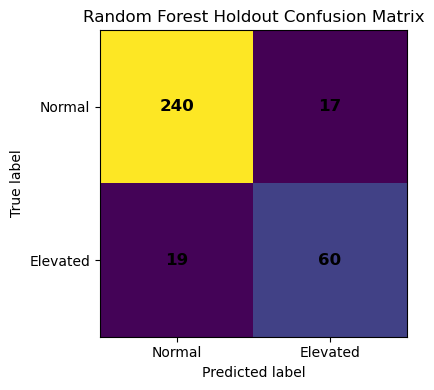


Random Forest feature importance
lag1            0.2414
lag168          0.2351
hour_cos        0.1268
lag24           0.1020
lag2            0.0654
roll24_std      0.0486
dow_sin         0.0428
hour_sin        0.0378
roll24_mean     0.0327
roll168_mean    0.0304
weekend         0.0242
dow_cos         0.0128
dtype: float64



Random Forest feature importance
lag1            0.2416
lag168          0.2347
hour_cos        0.1269
lag24           0.1026
lag2            0.0651
roll24_std      0.0488
dow_sin         0.0428
hour_sin        0.0375
roll24_mean     0.0326
roll168_mean    0.0303
weekend         0.0242
dow_cos         0.0128
dtype: float64


In [14]:
X_train, y_train = train[features], train["high_demand"]
X_test, y_test = test[features], test["high_demand"]

final_models = make_models()
final_results = {}
for name, model in final_models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    cm = confusion_matrix(y_test, pred)
    final_results[name] = {
        "accuracy": accuracy_score(y_test, pred),
        "precision": precision_score(y_test, pred),
        "recall": recall_score(y_test, pred),
        "f1": f1_score(y_test, pred),
        "roc_auc": roc_auc_score(y_test, prob),
        "confusion_matrix": cm
    }
    print(f"\n{name}")
    for metric in ["accuracy","precision","recall","f1","roc_auc"]:
        print(f"{metric}: {final_results[name][metric]:.6f}")
    print("confusion matrix:", cm, sep="\n")

rf = final_models["Random Forest"]
rf_pred = rf.predict(X_test)
rf_cm = confusion_matrix(y_test, rf_pred)
fig, ax = plt.subplots(figsize=(5,4))
im = ax.imshow(rf_cm)
for (i,j), value in np.ndenumerate(rf_cm):
    ax.text(j, i, str(value), ha="center", va="center", fontsize=12, fontweight="bold")
ax.set_xticks([0,1], ["Normal","Elevated"])
ax.set_yticks([0,1], ["Normal","Elevated"])
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_title("Random Forest Holdout Confusion Matrix")
plt.tight_layout(); plt.show()

importance = pd.Series(rf.feature_importances_, index=features).sort_values(ascending=False)
print("\nRandom Forest feature importance")
print(importance.round(4))

## Interpretation
The final holdout is the primary performance estimate. Random forest provides the stronger holdout F1 and ROC-AUC and identifies 59 of 79 elevated-demand hours. The result supports historical calls-for-service data as a **short-horizon operational planning signal** within this study period. It does not establish a staffing formula, predict confirmed crime, or demonstrate that performance will remain unchanged across seasons or jurisdictions.

The descriptive analysis also shows that call type and geography are not uniform: traffic calls make up the largest share of the selected categories, category-specific peak hours differ, and raw call volume varies across council districts. These geographic counts should not be interpreted as crime rates or intrinsic community risk.